In [86]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [87]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\eda_house_price_dataset.csv")

In [124]:
df.shape

(10289, 6)

In [125]:
df.columns

Index(['Size (sq. ft.)', 'Bedrooms', 'Bathrooms', 'Age of House (Years)',
       'Distance to City Center (Miles)', 'Price'],
      dtype='object')

In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10289 entries, 0 to 10299
Data columns (total 6 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Size (sq. ft.)                   10289 non-null  float64
 1   Bedrooms                         10289 non-null  float64
 2   Bathrooms                        10289 non-null  float64
 3   Age of House (Years)             10289 non-null  float64
 4   Distance to City Center (Miles)  10289 non-null  float64
 5   Price                            10289 non-null  float64
dtypes: float64(6)
memory usage: 562.7 KB


In [127]:
df.describe()

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
count,10289.000000,10289.000000,10289.000000,10289.000000,10289.000000,10289.000000
mean,2771.910153,2.975199,2.493371,25.019629,10.014317,124864.741568
std,1244.627213,1.387214,1.112622,14.470868,5.636493,88210.158997
min,600.051193,1.000000,1.000000,0.000000,0.102037,7.204593
25%,1711.378429,2.000000,1.000000,13.000000,5.295302,56123.542840
50%,2773.847581,3.000000,2.494543,25.016018,10.006183,107110.540100
75%,3814.264478,4.000000,3.000000,37.000000,14.755531,182130.443600
max,4998.757762,5.000000,4.000000,50.000000,19.998004,420486.748300


In [128]:
df.dtypes

Size (sq. ft.)                     float64
Bedrooms                           float64
Bathrooms                          float64
Age of House (Years)               float64
Distance to City Center (Miles)    float64
Price                              float64
dtype: object

In [129]:
df.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
Price                              0
dtype: int64

In [130]:
df.duplicated().sum()

np.int64(300)

In [131]:
df["Size (sq. ft.)"] = df["Size (sq. ft.)"].fillna(df["Size (sq. ft.)"].mean())
df["Bedrooms"] = df["Bedrooms"].fillna(df["Bedrooms"].mean())
df["Age of House (Years)"] = df["Age of House (Years)"].fillna(df["Age of House (Years)"].mean())
df["Distance to City Center (Miles)"] = df["Distance to City Center (Miles)"].fillna(df["Distance to City Center (Miles)"].mean())
df["Price"] = df["Price"].fillna(df["Price"].mean())

In [132]:
df.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
Price                              0
dtype: int64

In [133]:
df["Bathrooms"]=df["Bathrooms"].fillna(df["Bathrooms"].mean())

In [134]:
df.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
Price                              0
dtype: int64

In [135]:
df["Price"]=df["Price"].apply(lambda x:x*(-1) if x<0 else x*(1))

In [136]:
df

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
0,1543.388525,5.0,2.000000,21.0,5.363322,138900.290300
1,2546.092744,3.0,3.000000,12.0,8.940724,86109.931030
2,2480.852724,5.0,1.000000,18.0,3.543647,264942.561400
3,1343.314278,5.0,2.494543,41.0,17.081160,110053.768500
4,4894.488693,2.0,4.000000,6.0,16.646904,55148.743140
...,...,...,...,...,...,...
10295,4453.885567,1.0,2.494543,16.0,9.778924,47703.013640
10296,2773.847581,4.0,1.000000,45.0,5.021931,113370.801600
10297,4527.755529,4.0,1.000000,20.0,3.130250,341658.764900
10298,3967.391718,4.0,1.000000,37.0,16.872878,772.812653


In [137]:
model = LinearRegression()

In [138]:
x = df[["Size (sq. ft.)","Bedrooms","Bathrooms","Age of House (Years)","Distance to City Center (Miles)"]]

In [139]:
y = df["Price"]

In [140]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=4444)

In [141]:
x_train.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
dtype: int64

In [142]:
y_train

1707    136645.86380
35       82192.16314
9972    170298.79600
104     224535.49230
9064    100373.47720
            ...     
5210    188306.64040
4279     96734.08856
8097    259296.46610
7477    337022.41850
8367    233449.03530
Name: Price, Length: 8231, dtype: float64

In [143]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [144]:
y_predict = model.predict(x_test)

In [145]:
y_predict

array([200565.59875876, 166057.1929363 , 152972.55999339, ...,
       121917.71961527, 223492.44927115,  58933.62003531], shape=(2058,))

In [146]:
mae = mean_absolute_error(y_test,y_predict)

In [147]:
mae

59641.58497505033

In [148]:
mse = mean_squared_error(y_test,y_predict)

In [149]:
mse

5458054719.48945

In [150]:
rmse = root_mean_squared_error(y_test,y_predict)

In [151]:
rmse

73878.6486035678

In [152]:
r2 = r2_score(y_test,y_predict)

In [153]:
r2

0.3182397108191136

In [47]:
# df.columns
a = int(input("enter the size"))
b = int(input("enter the bed"))
c = int(input("enter the bath"))
d = int(input("enter the distans"))
e = int(input("enter milles"))
y_predict = model.predict([[a,b,c,d,e]])

enter the size 10
enter the bed 20
enter the bath 30
enter the distans 40
enter milles 60


C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [48]:
y_predict

array([12805.16475731])

In [50]:

import pandas as pd

# Import libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\eda_house_price_dataset.csv")

# Remove rows with missing target values
df = df.dropna(subset=["Price"])

# Remove invalid negative house prices
df = df[df["Price"] > 0]

# Independent and dependent variables
X = df.drop("Price", axis=1)
y = df["Price"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create preprocessing and model pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)


R2 Score: 0.9185268206584177
MAE: 19417.317305584234
MSE: 746805519.8689357
RMSE: 27327.742677889364


In [60]:
import matplotlib.pyplot as plt

ValueError: x and y must be the same size

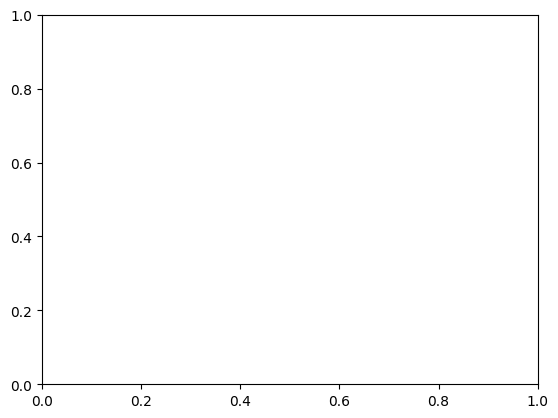

In [53]:
plt.scatter(x_train,y_train)

In [82]:
df.describe()

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
count,6451.000000,6451.000000,6453.000000,6440.000000,6448.000000,6657.000000
mean,3066.118251,3.183692,2.581590,24.610559,7.253306,144628.444859
std,1230.718875,1.392300,1.125171,14.697812,4.618498,94140.595233
min,600.051193,1.000000,1.000000,0.000000,0.102037,45.522015
25%,2083.994819,2.000000,2.000000,12.000000,3.396703,67490.986930
50%,3171.989698,3.000000,3.000000,25.000000,6.764869,130772.341700
75%,4138.879257,4.000000,4.000000,37.000000,10.470199,208723.262900
max,4998.757762,5.000000,4.000000,50.000000,19.899637,447373.485600


In [119]:
Q1 = 67490.98
Q3 = 208723.26

IQR = Q3-Q1

low_b = Q1-1.5*(IQR)
High_b = Q3+1.5*(IQR)
print(low_b)
print(High_b)
a = df[(df["Price"]<low_b) | (df["Price"]>High_b)]

-144357.44000000006
420571.68000000005


In [66]:
df.columns

Index(['Size (sq. ft.)', 'Bedrooms', 'Bathrooms', 'Age of House (Years)',
       'Distance to City Center (Miles)', 'Price'],
      dtype='object')

In [122]:
df.drop(a.index,inplace=True)

In [123]:
df

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
0,1543.388525,5.0,2.000000,21.0,5.363322,138900.290300
1,2546.092744,3.0,3.000000,12.0,8.940724,86109.931030
2,2480.852724,5.0,1.000000,18.0,3.543647,264942.561400
3,1343.314278,5.0,2.494543,41.0,17.081160,110053.768500
4,4894.488693,2.0,4.000000,6.0,16.646904,55148.743140
...,...,...,...,...,...,...
10295,4453.885567,1.0,2.494543,16.0,9.778924,47703.013640
10296,2773.847581,4.0,1.000000,45.0,5.021931,113370.801600
10297,4527.755529,4.0,1.000000,20.0,3.130250,341658.764900
10298,3967.391718,4.0,1.000000,37.0,16.872878,772.812653


In [154]:
import numpy as np

In [155]:
df.columns

Index(['Size (sq. ft.)', 'Bedrooms', 'Bathrooms', 'Age of House (Years)',
       'Distance to City Center (Miles)', 'Price'],
      dtype='object')

In [164]:
df['Price'].replace("",np.nan).isnull().sum()

np.int64(0)

In [166]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\eda_house_price_dataset.csv")

# Remove rows where target is missing
df = df.dropna(subset=["Price"])

# Separate X and y
X = df.drop("Price", axis=1)
y = df["Price"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build pipeline
model = LinearRegression()

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)


ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [167]:
import pandas as pd

In [168]:
df= pd.read_csv(r"C:\Users\Admin\Downloads\house_price_ml_practice_dirty.csv")

In [169]:
df.shape

(1208, 11)

In [170]:
df.columns

Index(['Property_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_years',
       'Distance_to_City_km', 'Location', 'Property_Type', 'Parking',
       'Furnishing', 'Price_INR'],
      dtype='object')

In [171]:
df.head()

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Location,Property_Type,Parking,Furnishing,Price_INR
0,P0749,1122.0,3.0,3.0,30.0,7.5,Central,Apartment,Yes,Furnished,9278577.0
1,P0513,2257.0,4.0,4.0,5.0,NaN,Suburban,Apartment,No,Unfurnished,12780511.0
2,P0871,1430.0,4.0,3.0,7.0,24.9,Suburban,Apartment,Yes,Unfurnished,8894828.0
3,P1002,2033.0,2.0,1.0,3.0,22.5,Central,Apartment,No,Furnished,12862090.0
4,P0588,663.0,1.0,1.0,2.0,5.5,Outskirts,Apartment,Yes,Furnished,4083418.0


In [172]:
df.tail()

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Location,Property_Type,Parking,Furnishing,Price_INR
1203,P1145,1161.0,1.0,1.0,9.0,16.6,Outskirts,Independent House,Yes,Furnished,7419228.0
1204,P0369,497.0,NaN,1.0,3.0,24.5,Suburban,Apartment,Yes,Unfurnished,3326062.0
1205,P0049,1907.0,3.0,3.0,6.0,NaN,Suburban,Villa,No,Semi-Furnished,16333559.0
1206,P0773,460.0,1.0,1.0,31.0,9.3,Suburban,Independent House,Yes,Semi-Furnished,4322685.0
1207,P0970,527.0,1.0,1.0,17.0,12.7,Outskirts,Apartment,No,Unfurnished,2169265.0


In [173]:
df.sample(10)

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Location,Property_Type,Parking,Furnishing,Price_INR
343,P0548,1720.0,3.0,3.0,34.0,11.8,Suburban,Independent House,Yes,Semi-Furnished,12030344.0
910,P0569,1831.0,4.0,4.0,33.0,2.5,Suburban,Apartment,No,NaN,10895851.0
799,P1051,1542.0,4.0,4.0,35.0,1.4,Central,Apartment,No,Furnished,10868941.0
89,P0537,1429.0,2.0,1.0,16.0,11.5,Suburban,Independent House,Yes,Furnished,10910621.0
468,P0755,1643.0,2.0,1.0,17.0,18.2,University Area,Apartment,No,Semi-Furnished,9688702.0
163,P1000,1552.0,3.0,2.0,31.0,23.5,Outskirts,Villa,No,Furnished,9738279.0
1116,P0742,NaN,3.0,3.0,35.0,24.5,NaN,Independent House,No,Semi-Furnished,12731263.0
403,P0316,NaN,3.0,2.0,18.0,16.4,Central,Apartment,No,Semi-Furnished,11913410.0
1117,P1140,1609.0,3.0,2.0,11.0,12.8,Central,Apartment,No,Furnished,11704596.0
806,P0337,2520.0,4.0,4.0,10.0,3.1,Suburban,Apartment,No,Semi-Furnished,17002066.0


In [174]:
df.isnull().sum()

Property_ID             0
Area_sqft              41
Bedrooms               30
Bathrooms              37
Age_years              31
Distance_to_City_km    36
Location               42
Property_Type          31
Parking                30
Furnishing             36
Price_INR              18
dtype: int64

In [175]:
df["Area_sqft"] = df["Area_sqft"].fillna(df["Area_sqft"].mean())

In [176]:
df["Bedrooms"] = df["Bedrooms"].fillna(df["Bedrooms"].mean())

In [177]:
df["Bathrooms"] = df["Bathrooms"].fillna(df["Bathrooms"].median())

In [178]:
df["Age_years"] = df["Age_years"].fillna(df["Age_years"].median())

In [180]:
df["Distance_to_City_km"]=df["Distance_to_City_km"].fillna(df["Distance_to_City_km"].mean())

In [182]:
a = df["Location"].mode()

In [184]:
df["Location"] = df["Location"].fillna(a[0])

In [187]:
a = df["Property_Type"].mode()

In [188]:
df["Property_Type"]= df["Property_Type"].fillna(a[0])

In [191]:
a = df["Parking"].mode()

In [192]:
df["Parking"] = df["Parking"].fillna(a[0])

In [198]:
a = df["Furnishing"].mode()
df["Furnishing"] = df["Furnishing"].fillna(a[0])
# Price_INR  

In [199]:
a = df["Price_INR"].mode()

In [200]:
df["Price_INR"] = df["Price_INR"].fillna(a[0])

In [201]:
df.isna().sum()

Property_ID            0
Area_sqft              0
Bedrooms               0
Bathrooms              0
Age_years              0
Distance_to_City_km    0
Location               0
Property_Type          0
Parking                0
Furnishing             0
Price_INR              0
dtype: int64

In [206]:
df["Furnishing"].value_counts()

Furnishing
Semi-furnished    576
Unfurnished       344
Furnished         288
Name: count, dtype: int64

In [203]:
df["Furnishing"] = df["Furnishing"].apply(lambda x:x.capitalize())

In [205]:
df.loc[df["Furnishing"]=="Semi furnished","Furnishing"]="Semi-furnished"

In [208]:
df.columns

Index(['Property_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_years',
       'Distance_to_City_km', 'Location', 'Property_Type', 'Parking',
       'Furnishing', 'Price_INR'],
      dtype='object')

In [209]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Property_ID          1208 non-null   object 
 1   Area_sqft            1208 non-null   float64
 2   Bedrooms             1208 non-null   float64
 3   Bathrooms            1208 non-null   float64
 4   Age_years            1208 non-null   float64
 5   Distance_to_City_km  1208 non-null   float64
 6   Location             1208 non-null   object 
 7   Property_Type        1208 non-null   object 
 8   Parking              1208 non-null   object 
 9   Furnishing           1208 non-null   object 
 10  Price_INR            1208 non-null   float64
dtypes: float64(6), object(5)
memory usage: 103.9+ KB


In [210]:
df.select_dtypes("float64")

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Price_INR
0,1122.0,3.000000,3.0,30.0,7.500000,9278577.0
1,2257.0,4.000000,4.0,5.0,12.636348,12780511.0
2,1430.0,4.000000,3.0,7.0,24.900000,8894828.0
3,2033.0,2.000000,1.0,3.0,22.500000,12862090.0
4,663.0,1.000000,1.0,2.0,5.500000,4083418.0
...,...,...,...,...,...,...
1203,1161.0,1.000000,1.0,9.0,16.600000,7419228.0
1204,497.0,2.780985,1.0,3.0,24.500000,3326062.0
1205,1907.0,3.000000,3.0,6.0,12.636348,16333559.0
1206,460.0,1.000000,1.0,31.0,9.300000,4322685.0


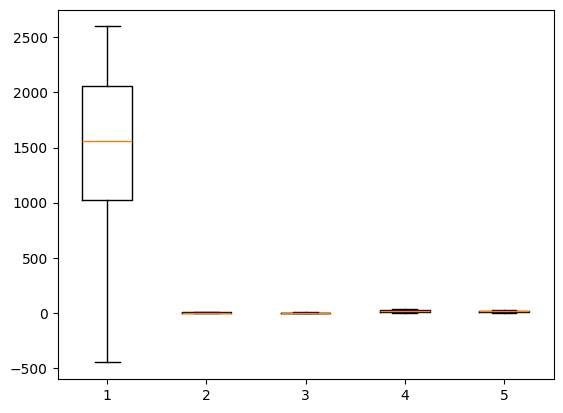

In [231]:
plt.boxplot(df[["Area_sqft","Bedrooms","Bathrooms","Age_years","Distance_to_City_km"]])
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x22516e16710>,
 'caps': [<matplotlib.lines.Line2D at 0x22516e16990>,
 'boxes': [<matplotlib.lines.Line2D at 0x22516e165d0>],
 'medians': [<matplotlib.lines.Line2D at 0x22516e16c10>],
 'fliers': [<matplotlib.lines.Line2D at 0x22516e16d50>],
 'means': []}

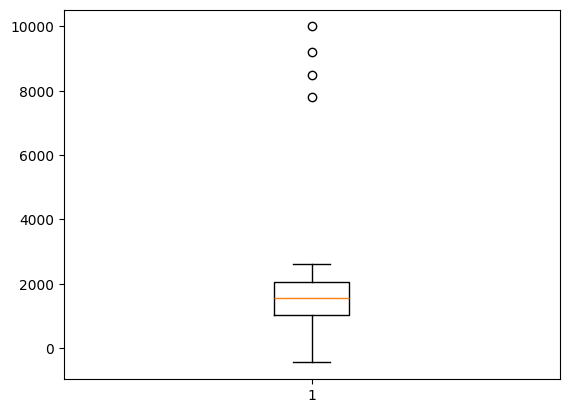

In [213]:
plt.boxplot(df["Area_sqft"])

{'whiskers': [<matplotlib.lines.Line2D at 0x22516fc5090>,
 'caps': [<matplotlib.lines.Line2D at 0x22516fc5310>,
 'boxes': [<matplotlib.lines.Line2D at 0x22516fc4f50>],
 'medians': [<matplotlib.lines.Line2D at 0x22516fc5590>],
 'fliers': [<matplotlib.lines.Line2D at 0x22516fc56d0>],
 'means': []}

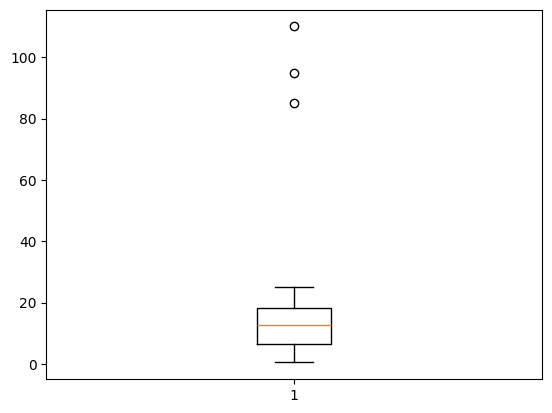

In [215]:
plt.boxplot(df["Distance_to_City_km"])

In [216]:
df.describe()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Price_INR
count,1208.000000,1208.000000,1208.000000,1208.000000,1208.000000,1.208000e+03
mean,1558.743787,2.780985,2.429636,17.053808,12.636348,1.040995e+07
std,742.320295,1.257124,1.132490,11.150975,8.068710,3.830323e+06
min,-450.000000,-1.000000,-1.000000,0.000000,0.500000,1.634671e+06
25%,1027.750000,2.000000,1.000000,8.000000,6.600000,7.272034e+06
50%,1558.743787,3.000000,2.000000,17.000000,12.600000,1.049355e+07
75%,2059.500000,4.000000,3.000000,26.000000,18.200000,1.353964e+07
max,10000.000000,5.000000,4.000000,120.000000,110.000000,1.976421e+07


In [228]:
Q1 = 6.60
Q3 = 18.20

IQR =Q3-Q1
low_A = Q1-1.5*(IQR)
hig_A = Q3+1.5*(IQR)
print(low_A)
a = df[(df["Distance_to_City_km"]<low_A) | (df["Distance_to_City_km"]>hig_A)]

-10.799999999999999


In [229]:
df.drop(a.index,inplace=True)

In [230]:
df

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_City_km,Location,Property_Type,Parking,Furnishing,Price_INR
0,P0749,1122.0,3.000000,3.0,30.0,7.500000,Central,Apartment,Yes,Furnished,9278577.0
1,P0513,2257.0,4.000000,4.0,5.0,12.636348,Suburban,Apartment,No,Unfurnished,12780511.0
2,P0871,1430.0,4.000000,3.0,7.0,24.900000,Suburban,Apartment,Yes,Unfurnished,8894828.0
3,P1002,2033.0,2.000000,1.0,3.0,22.500000,Central,Apartment,No,Furnished,12862090.0
4,P0588,663.0,1.000000,1.0,2.0,5.500000,Outskirts,Apartment,Yes,Furnished,4083418.0
...,...,...,...,...,...,...,...,...,...,...,...
1203,P1145,1161.0,1.000000,1.0,9.0,16.600000,Outskirts,Independent House,Yes,Furnished,7419228.0
1204,P0369,497.0,2.780985,1.0,3.0,24.500000,Suburban,Apartment,Yes,Unfurnished,3326062.0
1205,P0049,1907.0,3.000000,3.0,6.0,12.636348,Suburban,Villa,No,Semi-furnished,16333559.0
1206,P0773,460.0,1.000000,1.0,31.0,9.300000,Suburban,Independent House,Yes,Semi-furnished,4322685.0


In [232]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [233]:
x = df[["Area_sqft","Bedrooms","Bathrooms","Age_years","Distance_to_City_km"]]
y = df["Price_INR"]

In [234]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=555)

In [235]:
model = LinearRegression()

In [236]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [237]:
y_predict=model.predict(x_test)

In [239]:
y_predict.shape

(240,)

In [241]:
mae = mean_absolute_error(y_test,y_predict)

In [242]:
mae

1087745.2678986692

In [243]:
mse = mean_squared_error(y_test,y_predict)

In [244]:
mse

2240767051521.251

In [249]:
rmse = root_mean_squared_error(y_test,y_predict)

In [250]:
rmse

1496919.186703561

In [251]:
r11 = r2_score(y_test,y_predict)

In [252]:
r11

0.8438783922908245